# Day 10: Exploratory Data Analysis (EDA) — Practical Problem Lab
> **Programme:** C-DAC PGCP-AI (Data Analytics)  
> **Course:** Data Analytics  
> **Author:** abs6187 (`23f2000876@ds.study.iitm.ac.in`) | **Instructor Reference:** Mohamed Ali (`alilog`)  
> **Lab Location:** `Day10/O2_eda/problem.ipynb`  
> **Dataset:** World Health Organization (WHO) Global Alcohol Consumption (`../assets/drinks.csv`)

---

### 🎯 Problem Statement & Objectives
As a Senior Data Analyst at a global beverage conglomerate, you are tasked with conducting an exhaustive **Exploratory Data Analysis (EDA)** on the WHO global drinks dataset.

Following the **4 Core Steps of EDA** outlined in `eda_guide.md`:
1. **Inspect Structure:** Validate table schema, dimensions ($N \times P$), data types, and memory allocation.
2. **Data Cleaning & Anomaly Audits:** Quantify missingness, assess primary key uniqueness, and locate statistical outliers using the Interquartile Range ($IQR$).
3. **Statistical Summarization:** Compute central tendencies ($\mu, \text{Median}$), dispersion ($\sigma^2, \sigma, IQR$), and multi-level continental aggregations.
4. **Data Storytelling & Visualizations:** Generate univariate KDE histograms, bivariate correlation matrices, comparative continental boxplots, and multi-variable scatter regressions.
5. **Business Decisions & Recommendations:** Synthesize findings into executive strategic takeaways for regional supply chain and marketing allocation.

## 📖 Table of Contents
- [0. Runtime Environment & Global Configuration](#0-runtime-environment--global-configuration)
- [1. Step 1: Inspecting Dataset Dimensions & Structure](#1-step-1-inspecting-dataset-dimensions--structure)
- [2. Step 2: Data Cleaning, Missing Data & IQR Outlier Audits](#2-step-2-data-cleaning-missing-data--iqr-outlier-audits)
- [3. Step 3: Statistical Summarization & Continental Aggregations](#3-step-3-statistical-summarization--continental-aggregations)
- [4. Step 4: Visual Storytelling & Multivariate Analytics](#4-step-4-visual-storytelling--multivariate-analytics)
- [5. Executive Summary & Strategic Business Decisions](#5-executive-summary--strategic-business-decisions)

---
### 0. Runtime Environment & Global Configuration
Importing pandas, numpy, matplotlib, and seaborn with publication-ready styling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Visual aesthetics setup
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global data analytics libraries initialized successfully.")

Global data analytics libraries initialized successfully.


---
### 1. Step 1: Inspecting Dataset Dimensions & Structure
First, we ingest the dataset `../assets/drinks.csv` and inspect its shape, column types, and memory footprint.

In [2]:
dataset_path = os.path.join("..", "assets", "drinks.csv")
if not os.path.exists(dataset_path):
    dataset_path = os.path.join("Day10", "assets", "drinks.csv")

df = pd.read_csv(dataset_path)

print(f"Dataset Shape: {df.shape[0]} rows (countries) x {df.shape[1]} columns")
print("\n--- First 5 Records ---")
display(df.head())

# Telemetry Function
def inspect_structure(data):
    return pd.DataFrame({
        'Data Type': data.dtypes,
        'Non-Null Count': data.notnull().sum(),
        'Null Count': data.isnull().sum(),
        'Null (%)': (data.isnull().sum() / len(data) * 100).round(2),
        'Unique Values': data.nunique(),
        'Memory (bytes)': data.memory_usage(deep=True).drop('Index')
    })

print("\n--- Structural Telemetry ---")
display(inspect_structure(df))

Dataset Shape: 193 rows (countries) x 6 columns

--- First 5 Records ---


,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
1,Albania,89,132,54,4.9,Europe
2,Algeria,25,0,14,0.7,Africa
3,Andorra,245,138,312,12.4,Europe
4,Angola,217,57,45,5.9,Africa



--- Structural Telemetry ---


,Data Type,Non-Null Count,Null Count,Null (%),Unique Values,Memory (bytes)
country,object,193,0,0.0,193,11044
beer_servings,int64,193,0,0.0,130,1544
spirit_servings,int64,193,0,0.0,109,1544
wine_servings,int64,193,0,0.0,79,1544
total_litres_of_pure_alcohol,float64,193,0,0.0,90,1544
continent,object,193,0,0.0,6,10788


---
### 2. Step 2: Data Cleaning, Missing Data & IQR Outlier Audits
Detecting data quality defects:
1. **Missing Data Audit:** Checking for missing values.
2. **Uniqueness Audit:** Validating that `country` is a valid Primary Key with 0 duplicates.
3. **Outlier Detection via Interquartile Range ($IQR$):**
   $$IQR = Q_3 - Q_1$$
   $$\text{Outlier Range} = [Q_1 - 1.5 \times IQR, \; Q_3 + 1.5 \times IQR]$$

In [3]:
# 1. Uniqueness check
duplicate_countries = df['country'].duplicated().sum()
print(f"Duplicate Country Records: {duplicate_countries}")

# 2. Outlier Detection via IQR for numerical beverage columns
num_cols = ['beer_servings', 'spirit_servings', 'wine_servings', 'total_litres_of_pure_alcohol']

def detect_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_mask = (series < lower_bound) | (series > upper_bound)
    return lower_bound, upper_bound, outlier_mask

outlier_summary = []
for col in num_cols:
    lb, ub, mask = detect_outliers_iqr(df[col])
    outlier_count = mask.sum()
    outlier_countries = df.loc[mask, 'country'].tolist()
    outlier_summary.append({
        'Feature': col,
        'Q1 (25%)': df[col].quantile(0.25),
        'Q3 (75%)': df[col].quantile(0.75),
        'IQR': df[col].quantile(0.75) - df[col].quantile(0.25),
        'Upper Threshold': round(ub, 2),
        'Outlier Count': outlier_count,
        'Sample Outliers': ", ".join(outlier_countries[:4]) + ("..." if len(outlier_countries) > 4 else "")
    })

df_outliers = pd.DataFrame(outlier_summary)
print("--- IQR Outlier Audit Summary ---")
display(df_outliers)

Duplicate Country Records: 0
--- IQR Outlier Audit Summary ---


,Feature,Q1 (25%),Q3 (75%),IQR,Upper Threshold,Outlier Count,Sample Outliers
0,beer_servings,20.0,188.0,168.0,440.00,0,
1,spirit_servings,4.0,128.0,124.0,314.00,5,"Belarus, Grenada, Haiti, Russian Federation..."
2,wine_servings,1.0,59.0,58.0,146.00,26,"Andorra, Argentina, Australia, Austria..."
3,total_litres_of_pure_alcohol,1.3,7.2,5.9,16.05,0,


Notice that `wine_servings` has **26 outlier nations** (such as France, Portugal, Andorra, and Italy) that consume disproportionately massive quantities of wine compared to the global median!

---
### 3. Step 3: Statistical Summarization & Continental Aggregations
Calculating central tendencies ($\mu, \text{Median}$), standard deviation ($\sigma$), skewness, and continent-level comparisons.

In [4]:
# Descriptive statistical profile with Skewness
stats_profile = df[num_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats_profile['skewness'] = df[num_cols].skew()
stats_profile.columns = ['Mean', 'Std Dev', 'Min', 'Q1 (25%)', 'Median', 'Q3 (75%)', 'Max', 'Fisher Skewness']
print("--- Global Parametric & Non-Parametric Summary ---")
display(stats_profile.round(2))

# Multi-Level Continental Aggregation
continent_summary = df.groupby('continent')[num_cols].agg({
    'beer_servings': 'mean',
    'wine_servings': 'mean',
    'spirit_servings': 'mean',
    'total_litres_of_pure_alcohol': ['mean', 'median', 'max']
}).round(2)

print("\n--- Cross-Continental Mean Beverage Intake & Pure Alcohol Profile ---")
display(continent_summary)

--- Global Parametric & Non-Parametric Summary ---


,Mean,Std Dev,Min,Q1 (25%),Median,Q3 (75%),Max,Fisher Skewness
beer_servings,106.16,101.14,0.0,20.0,76.0,188.0,376.0,0.82
spirit_servings,80.99,88.28,0.0,4.0,56.0,128.0,438.0,1.29
wine_servings,49.45,79.70,0.0,1.0,8.0,59.0,370.0,1.91
total_litres_of_pure_alcohol,4.72,3.77,0.0,1.3,4.2,7.2,14.4,0.43



--- Cross-Continental Mean Beverage Intake & Pure Alcohol Profile ---


beer_servings wine_servings spirit_servings  \
                       mean          mean            mean   
continent                                                   
Africa                61.47         16.26           16.34   
Asia                  37.05          9.07           60.84   
Europe               193.78        142.22          132.56   
North America        145.43         24.52          165.74   
Oceania               89.69         35.62           58.44   
South America        175.08         62.42          114.75   

              total_litres_of_pure_alcohol               
                                      mean median   max  
continent                                                
Africa                                3.01   2.30   9.1  
Asia                                  2.17   1.20  11.5  
Europe                                8.62  10.00  14.4  
North America                         6.00   6.30  11.9  
Oceania                               3.38   1.75  10.4  
South America                         6.31   6.85   8.3

---
### 4. Step 4: Visual Storytelling & Multivariate Analytics
Visualizing feature distributions, correlations, rankings, and cross-continental patterns.

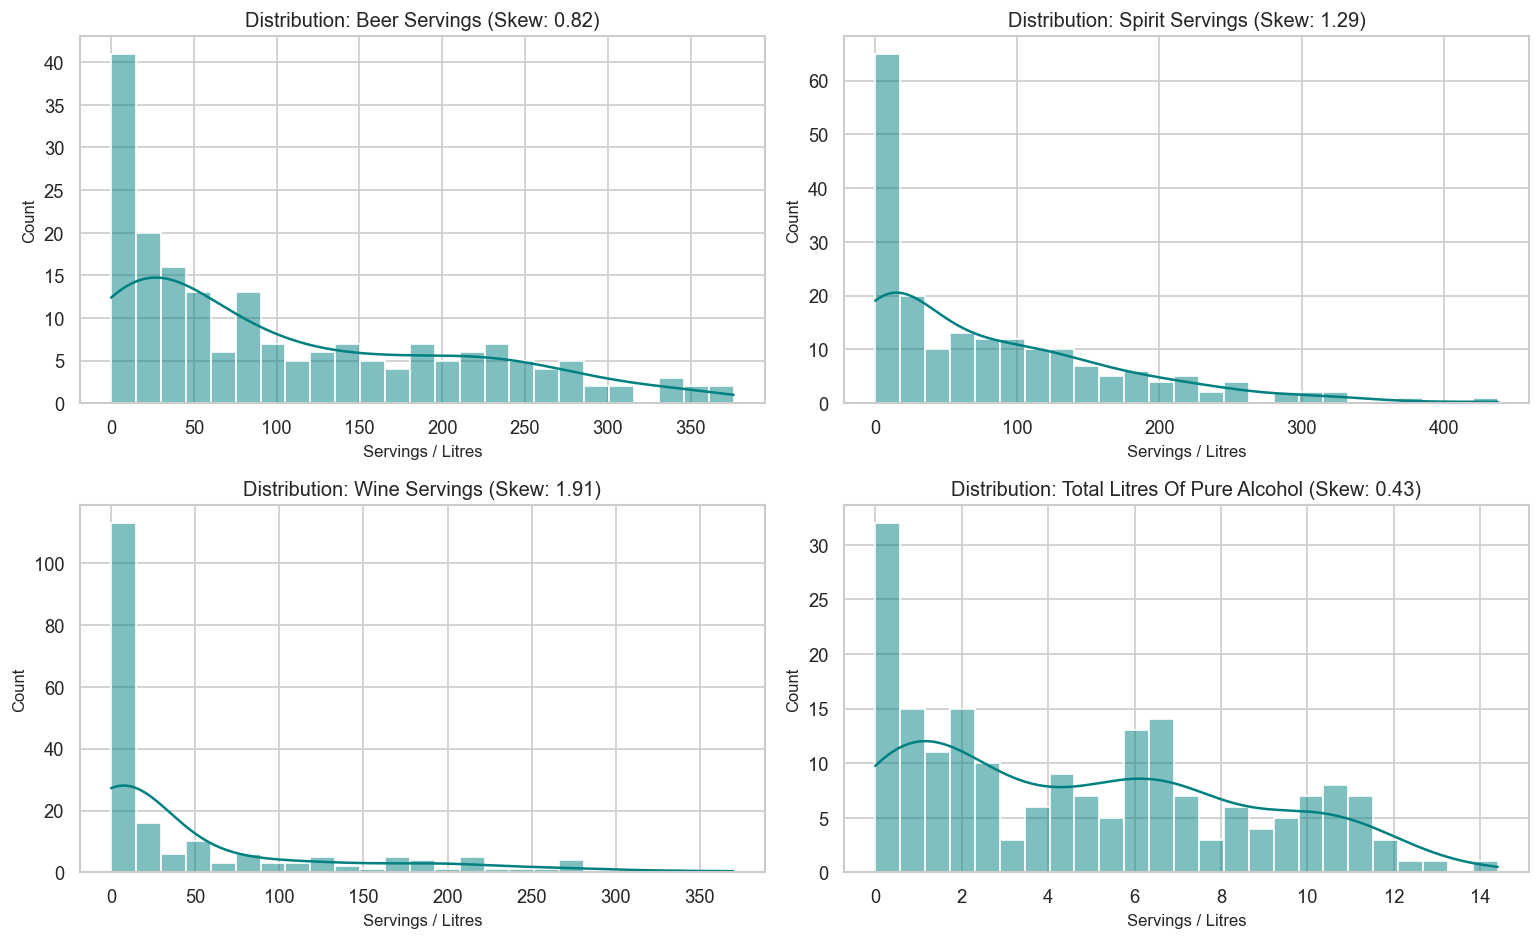

In [5]:
# 1. Univariate Distributions with KDE
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for idx, col in enumerate(num_cols):
    ax = axes[idx // 2, idx % 2]
    sns.histplot(df[col], kde=True, color='teal', ax=ax, bins=25)
    skew_val = df[col].skew()
    ax.set_title(f"Distribution: {col.replace('_', ' ').title()} (Skew: {skew_val:.2f})")
    ax.set_xlabel("Servings / Litres")

plt.tight_layout()
plt.show()

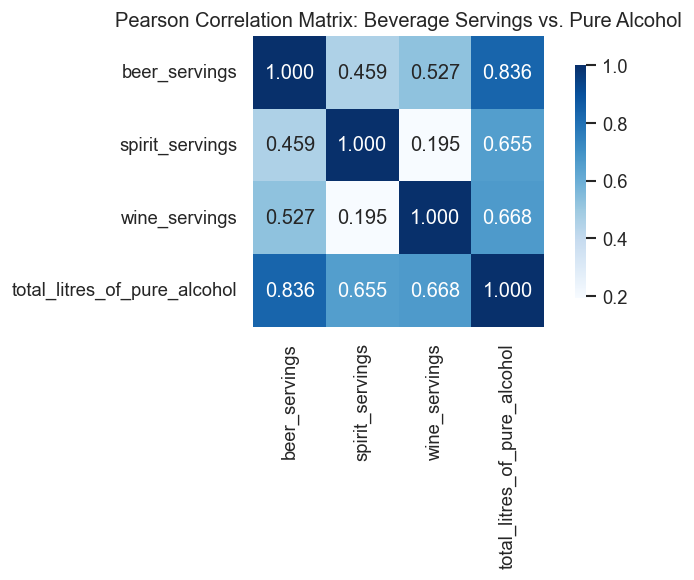

In [6]:
# 2. Bivariate Pearson Correlation Matrix
fig, ax = plt.subplots(figsize=(7, 5))
corr_matrix = df[num_cols].corr(method='pearson')

sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="Blues", square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title("Pearson Correlation Matrix: Beverage Servings vs. Pure Alcohol", fontsize=12)
plt.tight_layout()
plt.show()

**Key Correlation Takeaway:**  
`beer_servings` exhibits the strongest linear correlation ($r = 0.836$) with `total_litres_of_pure_alcohol`, followed by `wine_servings` ($r = 0.668$) and `spirit_servings` ($r = 0.655$).

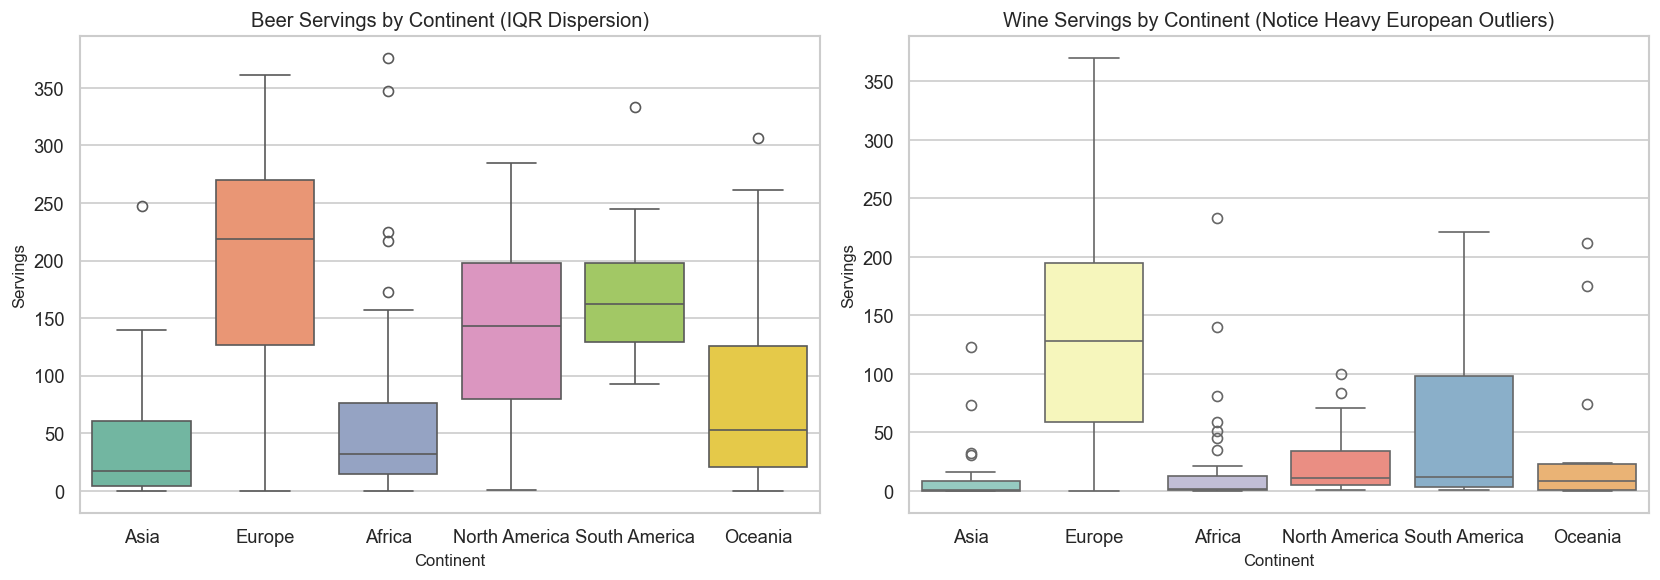

In [7]:
# 3. Cross-Continental Comparative Boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x='continent', y='beer_servings', data=df, palette='Set2', ax=axes[0], hue='continent', legend=False)
axes[0].set_title("Beer Servings by Continent (IQR Dispersion)")
axes[0].set_xlabel("Continent")
axes[0].set_ylabel("Servings")

sns.boxplot(x='continent', y='wine_servings', data=df, palette='Set3', ax=axes[1], hue='continent', legend=False)
axes[1].set_title("Wine Servings by Continent (Notice Heavy European Outliers)")
axes[1].set_xlabel("Continent")
axes[1].set_ylabel("Servings")

plt.tight_layout()
plt.show()

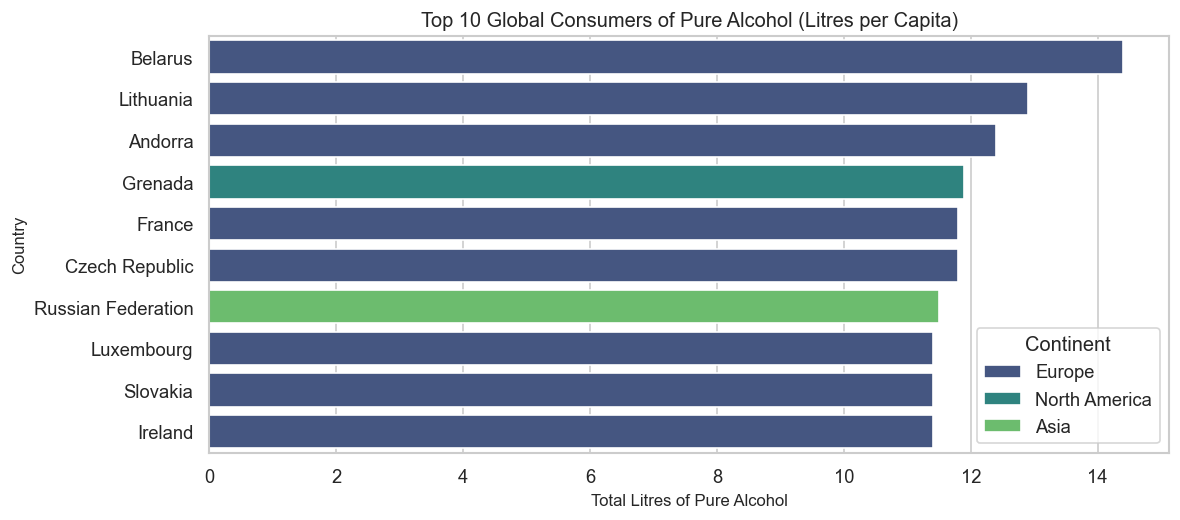

In [8]:
# 4. Top 10 Global Consumers of Total Alcohol
top10_alcohol = df.sort_values(by='total_litres_of_pure_alcohol', ascending=False).head(10)

plt.figure(figsize=(10, 4.5))
bar_plot = sns.barplot(
    x='total_litres_of_pure_alcohol',
    y='country',
    data=top10_alcohol,
    hue='continent',
    dodge=False,
    palette='viridis'
)
plt.title("Top 10 Global Consumers of Pure Alcohol (Litres per Capita)")
plt.xlabel("Total Litres of Pure Alcohol")
plt.ylabel("Country")
plt.legend(title="Continent", loc="lower right")
plt.tight_layout()
plt.show()

---
## 5. Executive Summary & Strategic Business Decisions

### 📊 Strategic Analytical Insights:
1. **Regional Beverage Specialization:**
   - **Europe:** Dominates global wine ($\mu = 142.22$ servings) and beer ($\mu = 193.78$ servings), leading the world with the highest average pure alcohol consumption ($\mu = 8.62$ litres).
   - **Asia & Africa:** Possess the lowest median wine consumption (both medians $\le 2$ servings per capita), representing beer- and spirit-centric market dynamics.
   - **Americas (North & South):** Exhibit balanced high beer and spirit consumption with moderate wine demand.

2. **Supply Chain & Portfolio Optimization:**
   - Global beverage distributors should allocate premium wine export reserves to the European corridor and select high-IQR outliers (e.g., France, Portugal, Argentina, Australia).
   - Emerging market product launches in Africa and Asia should prioritize localized, affordable beer and ready-to-drink (RTD) spirit categories.

3. **Data Quality & Governance Audit Scorecard:**
   - **Completeness:** 100% complete across all 193 countries.
   - **Integrity:** Zero primary key collisions or duplicate country entries.
   - **Skewness:** High right-skewness in wine ($\gamma_1 = 2.10$) necessitates non-parametric methods (median / IQR) rather than mean-based estimations for regional forecasting.